In [185]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [187]:
df = pd.read_csv("titanic.csv")

# print(data)
df.head()
df.shape # (891,11)
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [188]:
df["Age"] = df["Age"].fillna(df["Age"].mean())

df["Cabin"] = df["Cabin"].fillna("Unknown")

df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

df.isnull().sum()

df.duplicated().sum()

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


In [189]:
bins = [0,12,18,30,50,100]

labels = ["Child","Teen","Young Adult","Adult","Senior"]

df["Age_group"] = pd.cut(df["Age"],bins=bins,labels=labels)

not_survived = df[df["Survived"] == 0]

survived_passenger = df[df["Survived"] == 1]

print(survived_passenger.shape[0])
print(not_survived.shape[0])

342
549


In [190]:
male_survived = df[(df["Sex"] == "male") & (df["Survived"] == 1)]

print(male_survived.shape[0])

female_survived = df[(df["Sex"] == "female") & (df["Survived"] == 1)]

print(female_survived.shape[0])

109
233


In [191]:
first_class_survived = df[(df["Pclass"] == 1) & (df["Survived"] == 1)]

second_class_survived = df[(df["Pclass"] == 2) & (df["Survived"] == 1)]

third_class_survived = df[(df["Pclass"] == 3) & (df["Survived"] == 1)]

print(first_class_survived.shape[0])
print(second_class_survived.shape[0])
print(third_class_survived.shape[0])

136
87
119


In [225]:
age_group_survived = survived_passenger.groupby("Age_group").count()

print(age_group_survived["Survived"])

Age_group
Child           40
Teen            30
Young Adult    148
Adult          102
Senior          22
Name: Survived, dtype: int64


D:\Temp\ipykernel_5188\1123319484.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_group_survived = survived_passenger.groupby("Age_group").count()


In [193]:
fare_survival = survived_passenger["Fare"].mean()
print(fare_survival)

not_survival_fare = not_survived["Fare"].mean()
print(not_survival_fare)

48.39540760233918
22.117886885245902


In [194]:
no_spouse_survival = survived_passenger[survived_passenger['SibSp'] == 0]
one_spouse_survival = survived_passenger[survived_passenger['SibSp'] == 1]
two_spouse_survival = survived_passenger[survived_passenger['SibSp'] == 2]

print("Survived passengers without siblings/spouse:",len(no_spouse_survival))
print("Survived passengers with one siblings/spouse:",len(one_spouse_survival))
print("Survived passengers with two siblings/spouse:",len(two_spouse_survival))

Survived passengers without siblings/spouse: 210
Survived passengers with one siblings/spouse: 112
Survived passengers with two siblings/spouse: 13


In [195]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_group
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.2500,Unknown,S,Young Adult
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000000,1,0,PC 17599,71.2833,C85,C,Adult
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.9250,Unknown,S,Young Adult
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,113803,53.1000,C123,S,Adult
4,5,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.0500,Unknown,S,Adult
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.000000,0,0,211536,13.0000,Unknown,S,Young Adult
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.000000,0,0,112053,30.0000,B42,S,Young Adult
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,29.699118,1,2,W./C. 6607,23.4500,Unknown,S,Young Adult
889,890,1,1,"Behr, Mr. Karl Howell",male,26.000000,0,0,111369,30.0000,C148,C,Young Adult


In [196]:
no_parent_or_child_survival = survived_passenger[survived_passenger['Parch'] == 0]
one_parent_or_child_survival = survived_passenger[survived_passenger['Parch'] == 1]
two_parent_or_child_survival = survived_passenger[survived_passenger['Parch'] == 2]
three_parent_or_child_survival = survived_passenger[survived_passenger['Parch'] == 3]

print("Survived passengers without parent or child:",len(no_parent_or_child_survival))
print("Survived passengers with one parent or child:",len(one_parent_or_child_survival))
print("Survived passengers with two parent or child:",len(two_parent_or_child_survival))
print("Survived passengers with three parent or child:",len(three_parent_or_child_survival))

Survived passengers without parent or child: 233
Survived passengers with one parent or child: 65
Survived passengers with two parent or child: 40
Survived passengers with three parent or child: 3


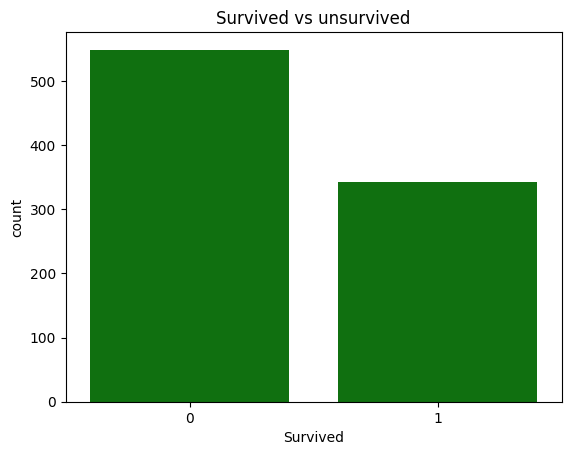

In [242]:
sns.countplot(data=df, x="Survived",color='green')
plt.title("Survived vs unsurvived")
plt.show()

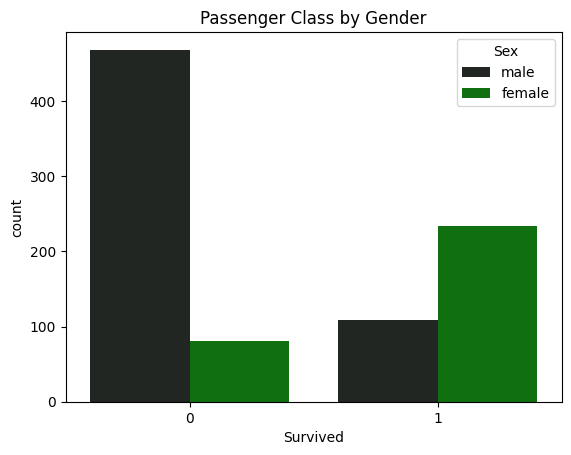

In [212]:
sns.countplot(data=df, x="Survived",color='green',hue="Sex",palette='dark:green') # Survived Passenger by gender
plt.title("Passenger Class by Gender")
plt.show()

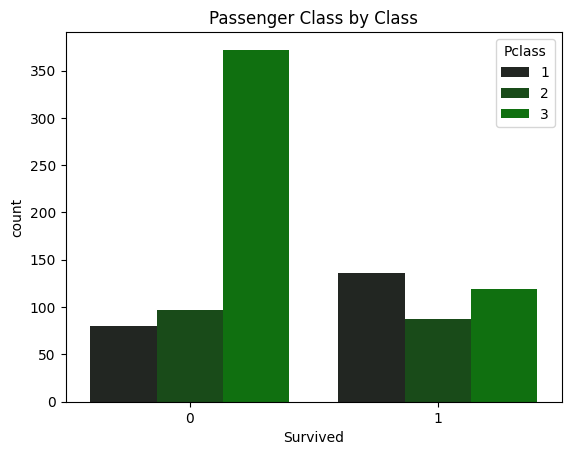

In [243]:
sns.countplot(data=df, x="Survived",color='green',hue="Pclass",palette='dark:green') # Survived Passenger by class
plt.title("Passenger Class by Class")
plt.show()

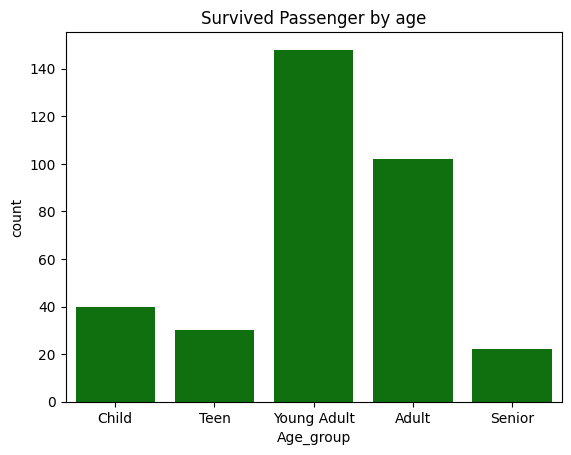

In [250]:
sns.countplot(data=survived_passenger,x='Age_group',color='green') # Survived Passenger by age
plt.title("Survived Passenger by age")
plt.show()

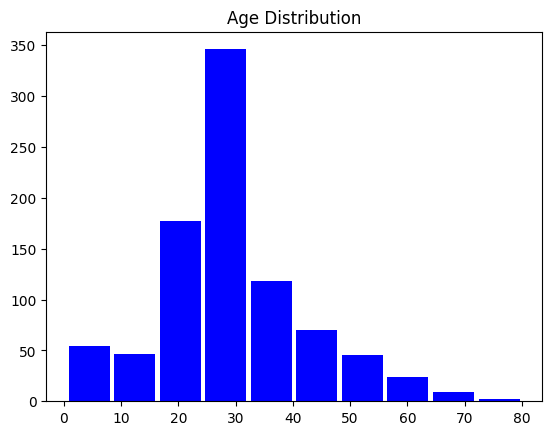

In [251]:
plt.hist(data=df,bins=10,x='Age',rwidth=0.9,color='blue')  # Age Distribution
plt.title("Age Distribution")
plt.show()

In [259]:
result = df.groupby('Survived')["Fare"].agg(
  ["sum","mean"]
)
result

,sum,mean
Survived,,
0,12142.7199,22.117887
1,16551.2294,48.395408


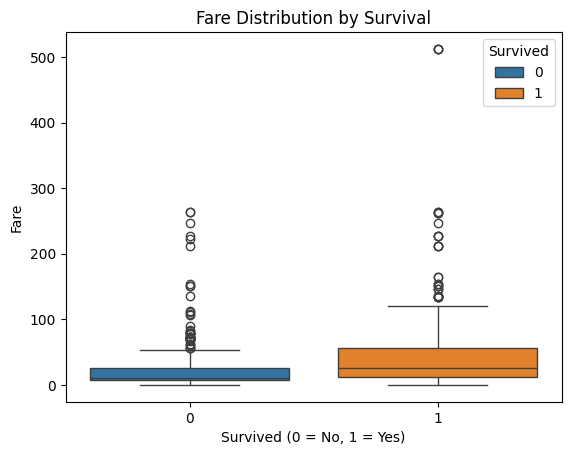

In [267]:
sns.boxplot(data=df, x='Survived', y='Fare', hue='Survived')

plt.title("Fare Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Fare")

plt.show()